# 🚀 Startup Success/Failure Prediction —> End-to-End ML Model Building

**A complete beginner-to-production workflow covering:**
1. Data Load
2. Data Analysis (EDA)
3. Data Cleaning
4. Feature Engineering (drop unneeded columns + feature selection)
5. Data Transformation
6. Train/Test Split (X, y)
7. Model Training (compare multiple models on accuracy)
8. Pipeline Creation (final deployable object)

Dataset: `startup_success_dataset.csv` (5000 rows)
Target column: `success` (1 = succeeded, 0 = failed)


## 1. Data Load

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 4)

df = pd.read_csv('startup_success_dataset.csv')
df.head()


,startup_id,founded_year,sector,country,city_tier,num_founders,founder_avg_experience_years,has_prior_startup_experience,has_technical_cofounder,team_size,...,market_size_billion_usd,num_active_competitors,product_launch_months_after_founding,num_patents_filed,has_female_founder,monthly_active_users_k,mom_revenue_growth_pct,customer_retention_rate_pct,nps_score,success
0,STU20000,2018,Logistics,India,Tier-1 Hub,2,5.7,0,1,9,...,3.74,6,8,2.0,0,2.3,19.3,69.7,57.0,0
1,STU20001,2023,E-commerce,Singapore,Tier-2 City,3,19.6,0,1,23,...,4.39,8,12,1.0,0,3.3,-5.3,40.9,91.0,1
2,STU20002,2020,Gaming,India,Tier-2 City,3,10.7,0,1,43,...,1.86,5,8,0.0,0,1.6,-3.2,58.4,-18.0,1
3,STU20003,2017,EdTech,Singapore,Tier-1 Hub,1,8.5,0,1,8,...,6.62,5,2,0.0,0,5.3,9.0,65.3,-7.0,1
4,STU20004,2017,AI/ML,India,Tier-1 Hub,2,6.0,0,1,10,...,3.61,8,4,0.0,1,1.3,3.3,78.0,4.0,0


In [3]:
import sys
print(sys.executable)

c:\Users\Admin\Desktop\Data Science Aishwarya\DS Project\test\test\Scripts\python.exe


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 24 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   startup_id                            5000 non-null   str    
 1   founded_year                          5000 non-null   int64  
 2   sector                                5000 non-null   str    
 3   country                               5000 non-null   str    
 4   city_tier                             5000 non-null   str    
 5   num_founders                          5000 non-null   int64  
 6   founder_avg_experience_years          5000 non-null   float64
 7   has_prior_startup_experience          5000 non-null   int64  
 8   has_technical_cofounder               5000 non-null   int64  
 9   team_size                             5000 non-null   int64  
 10  funding_stage                         5000 non-null   str    
 11  total_funding_usd_million   

## 2. Data Analysis (EDA)

Before touching the data, let's understand it: structure, missing values, target balance,
and which features actually relate to the target.


In [5]:
# Basic statistical summary
df.describe()

,founded_year,num_founders,founder_avg_experience_years,has_prior_startup_experience,has_technical_cofounder,team_size,total_funding_usd_million,num_funding_rounds,monthly_burn_rate_usd_k,market_size_billion_usd,num_active_competitors,product_launch_months_after_founding,num_patents_filed,has_female_founder,monthly_active_users_k,mom_revenue_growth_pct,customer_retention_rate_pct,nps_score,success
count,5000.000000,5000.000000,5000.00000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000,5000.0000,4853.000000,5000.000000,4849.000000,4844.000000,5000.000000,4858.000000,5000.000000
mean,2018.992400,2.255800,7.47208,0.27760,0.615000,22.545400,10.944596,2.085000,202.68054,6.343636,5.988200,11.9598,0.396456,0.237400,27.382883,7.760714,71.695360,30.816385,0.495800
std,3.173509,0.891361,4.26059,0.44786,0.486644,25.976206,23.293153,1.224285,242.65509,9.316176,2.425704,6.6307,0.631872,0.425532,84.400477,12.094704,16.046134,24.638077,0.500032
min,2014.000000,1.000000,0.20000,0.00000,0.000000,2.000000,0.030000,1.000000,1.00000,0.070000,0.000000,1.0000,0.000000,0.000000,0.000000,-32.000000,14.600000,-63.000000,0.000000
25%,2016.000000,2.000000,4.30000,0.00000,0.000000,8.000000,0.610000,1.000000,71.07500,1.617500,4.000000,6.0000,0.000000,0.000000,2.500000,-0.300000,61.500000,14.000000,0.000000
50%,2019.000000,2.000000,6.70000,0.00000,1.000000,15.000000,2.080000,2.000000,131.85000,3.360000,6.000000,12.0000,0.000000,0.000000,7.500000,7.600000,73.900000,31.000000,0.000000
75%,2022.000000,3.000000,9.70000,1.00000,1.000000,27.000000,10.110000,3.000000,245.40000,7.212500,7.000000,18.0000,1.000000,0.000000,21.300000,15.800000,84.300000,47.000000,1.000000
max,2024.000000,4.000000,30.00000,1.00000,1.000000,448.000000,300.040000,6.000000,4945.00000,174.630000,18.000000,23.0000,4.000000,1.000000,2652.500000,45.900000,99.800000,100.000000,1.000000


Columns with missing values:
mom_revenue_growth_pct    156
monthly_active_users_k    151
num_patents_filed         147
nps_score                 142
dtype: int64


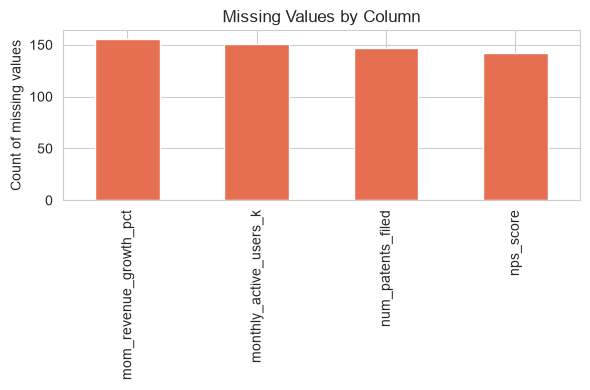

In [6]:
# Missing values check
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
print(missing)

plt.figure(figsize=(6,4))
missing.plot(kind='bar', color='#e76f51')
plt.title('Missing Values by Column')
plt.ylabel('Count of missing values')
plt.tight_layout()
plt.show()

success
0    2521
1    2479
Name: count, dtype: int64


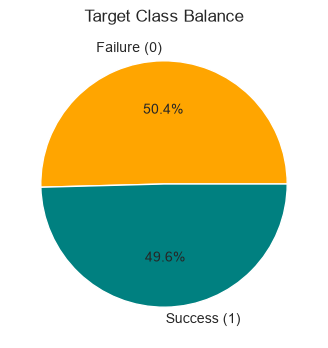

In [7]:
# Target variable balance
print(df['success'].value_counts())

plt.figure(figsize=(4,4))
df['success'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                    labels=['Failure (0)', 'Success (1)'],
                                    colors=['orange', 'teal'])
plt.title('Target Class Balance')
plt.show()


founder_avg_experience_years            0.357587
num_funding_rounds                      0.319996
total_funding_usd_million               0.275544
has_prior_startup_experience            0.241027
num_active_competitors                 -0.193413
has_technical_cofounder                 0.135982
mom_revenue_growth_pct                  0.114221
nps_score                               0.059920
num_patents_filed                       0.054122
team_size                              -0.052671
monthly_burn_rate_usd_k                -0.051312
customer_retention_rate_pct             0.048559
num_founders                            0.020588
product_launch_months_after_founding   -0.015647
monthly_active_users_k                  0.011023
founded_year                            0.007039
has_female_founder                     -0.003304
market_size_billion_usd                 0.001451
Name: success, dtype: float64


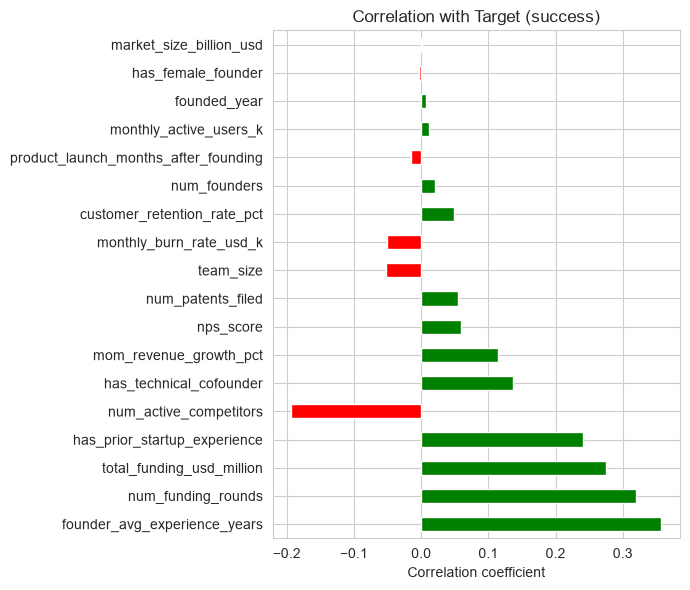

In [8]:
# Correlation of numeric features with the target — tells us which raw
# features already carry signal, and which look like noise
numeric_df = df.select_dtypes(include=[int,float])
target_corr = numeric_df.corr()['success'].drop('success').sort_values(key=abs, ascending=False)
print(target_corr)

plt.figure(figsize=(7,6))
target_corr.plot(kind='barh', color=['green' if v > 0 else 'red' for v in target_corr])
plt.title('Correlation with Target (success)')
plt.xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()


**Observations from EDA:**
- Target is well balanced (~49% success / ~51% failure) — no resampling needed.
- A handful of numeric columns (`nps_score`, `num_patents_filed`, `mom_revenue_growth_pct`,
  `monthly_active_users_k`) have a small percentage of missing values — needs imputation.
- `founder_avg_experience_years`, `num_funding_rounds`, `total_funding_usd_million`, and
  `has_prior_startup_experience` show the strongest correlation with success.
- Some columns (`market_size_billion_usd`, `founded_year`, `has_female_founder`,
  `product_launch_months_after_founding`, `monthly_active_users_k`, `num_founders`) show
  almost **zero correlation** with the target — candidates for removal in Feature Engineering.


## 3. Data Cleaning

Steps: remove duplicates, check/handle outliers, confirm data types are correct.
(Missing value **imputation** itself is deliberately deferred to the Pipeline step —
so imputation values are learned from training data only, not the full dataset —
but we inspect and understand the missingness here.)


In [9]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape after dropping duplicates:", df.shape)


Duplicate rows: 0
Shape after dropping duplicates: (5000, 24)


In [10]:
# Outlier check on key numeric columns using boxplots
outlier_check_cols = ['team_size', 'monthly_burn_rate_usd_k', 'total_funding_usd_million',
                       'monthly_active_users_k']

<Axes: >

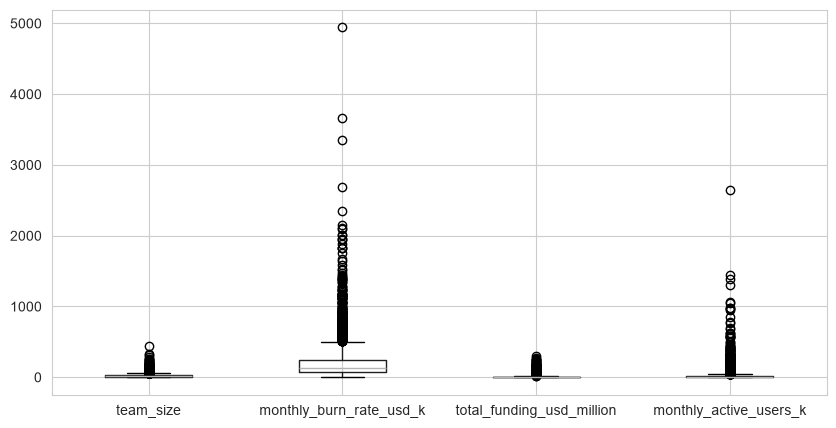

In [11]:
plt.figure(figsize=(10,5))
df[outlier_check_cols].boxplot()

In [12]:
# Confirm data types are sensible
df.dtypes

startup_id                                  str
founded_year                              int64
sector                                      str
country                                     str
city_tier                                   str
num_founders                              int64
founder_avg_experience_years            float64
has_prior_startup_experience              int64
has_technical_cofounder                   int64
team_size                                 int64
funding_stage                               str
total_funding_usd_million               float64
num_funding_rounds                        int64
monthly_burn_rate_usd_k                 float64
market_size_billion_usd                 float64
num_active_competitors                    int64
product_launch_months_after_founding      int64
num_patents_filed                       float64
has_female_founder                        int64
monthly_active_users_k                  float64
mom_revenue_growth_pct                  

## 4. Feature Engineering

**a) Drop columns that are not useful:**
- `startup_id` — unique identifier, no predictive value
- `founded_year`, `market_size_billion_usd`, `has_female_founder`,
  `product_launch_months_after_founding`, `monthly_active_users_k`, `num_founders`
  — all showed near-zero correlation with the target during EDA


**b) Formal feature selection** 
the strongest predictors on the training data.


In [13]:
# a) Drop unneeded columns
drop_cols = ['startup_id', 'founded_year', 'market_size_billion_usd', 'has_female_founder',
             'product_launch_months_after_founding', 'monthly_active_users_k', 'num_founders']

df_fe = df.drop(columns=drop_cols)
print("Remaining columns:", df_fe.columns.tolist())

Remaining columns: ['sector', 'country', 'city_tier', 'founder_avg_experience_years', 'has_prior_startup_experience', 'has_technical_cofounder', 'team_size', 'funding_stage', 'total_funding_usd_million', 'num_funding_rounds', 'monthly_burn_rate_usd_k', 'num_active_competitors', 'num_patents_filed', 'mom_revenue_growth_pct', 'customer_retention_rate_pct', 'nps_score', 'success']


Feature Importance (Decision Tree):
total_funding_usd_million       0.244906
founder_avg_experience_years    0.204870
mom_revenue_growth_pct          0.085229
num_active_competitors          0.085015
monthly_burn_rate_usd_k         0.082477
customer_retention_rate_pct     0.076211
nps_score                       0.056140
has_prior_startup_experience    0.054429
team_size                       0.053484
has_technical_cofounder         0.025725
num_patents_filed               0.016090
num_funding_rounds              0.015422
dtype: float64


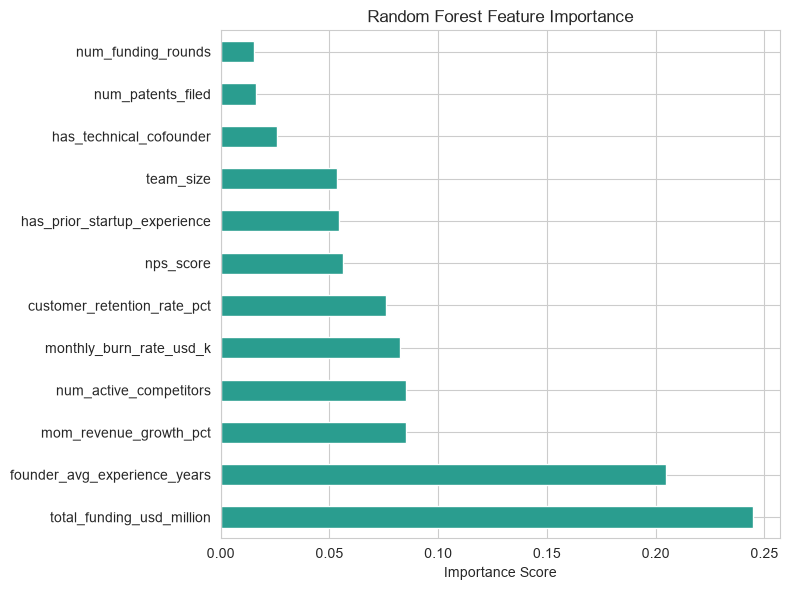

In [ ]:
# c) Feature Selection using DT (Numeric Features Only)

from sklearn.tree import DecisionTreeClassifier

# Select only numeric columns
numeric_cols = df_fe.select_dtypes(include=[int,float]).columns.tolist()
numeric_cols.remove('success')

# Temporary imputation for feature importance
X_rank = df_fe[numeric_cols].fillna(df_fe[numeric_cols].median())
y_rank = df_fe['success']

# Train decision tree
dt = DecisionTreeClassifier(random_state=42)

dt.fit(X_rank, y_rank)

# Feature Importance
feature_scores = (pd.Series(dt.feature_importances_, index=numeric_cols).sort_values(ascending=False))

print("Feature Importance (Decision Tree):")
print(feature_scores)

# Plot
plt.figure(figsize=(8,6))
feature_scores.plot(kind='barh', color='#2a9d8f')
plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

## 5. Data Transformation

We need two different transformations:
- **Numeric columns** → impute missing values (median) + scale (StandardScaler)
- **Categorical columns** → impute missing values (most frequent) + one-hot encode

⚠️ **Important:** we only *define* these transformations here for understanding.
We do **not** fit them on the full dataset — fitting on the full dataset before
splitting would leak information from the test set into training (data leakage).
The actual fitting happens strictly on the training set inside the Pipeline (Steps 6–8).


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

target = 'success'
numeric_features = df_fe.select_dtypes(include=[int,float]).columns.tolist()
numeric_features.remove(target)
categorical_features = df_fe.select_dtypes(include='object').columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

preprocessor


Numeric features: ['founder_avg_experience_years', 'has_prior_startup_experience', 'has_technical_cofounder', 'team_size', 'total_funding_usd_million', 'num_funding_rounds', 'monthly_burn_rate_usd_k', 'num_active_competitors', 'num_patents_filed', 'mom_revenue_growth_pct', 'customer_retention_rate_pct', 'nps_score']
Categorical features: ['sector', 'country', 'city_tier', 'funding_stage']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 6. Split into X and y

Now we split into features (X) and target (y), then into train/test sets — **before**
any transformation is actually fitted, to keep the test set truly unseen.


In [16]:
from sklearn.model_selection import train_test_split

X = df_fe.drop(columns=[target])
y = df_fe[target]

xtrain, xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42)

## 7. Model Training

We train **multiple classifiers** on the same preprocessed features and compare them
using **accuracy only**. The preprocessing step is fitted
on `X_train` only, then applied to both `X_train` and `X_test`.


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import accuracy_score

# Fit preprocessor on training data only, transform both sets
X_train_transformed = preprocessor.fit_transform(xtrain, ytrain)
X_test_transformed = preprocessor.transform(xtest)

print("Transformed training shape:", X_train_transformed.shape)


Transformed training shape: (4000, 40)


In [18]:
candidates = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Support Vector Machine': SVC()}


for name,model in candidates.items():
    model.fit(X_train_transformed, ytrain)
    print(f"Model Name: {model}")
    print(f"Train Accuracy: {model.score(X_train_transformed,ytrain)}")
    print(f"Test Accuracy: {model.score(X_test_transformed,ytest)}")
    print('-'*100)


Model Name: LogisticRegression()
Train Accuracy: 0.80575
Test Accuracy: 0.834
----------------------------------------------------------------------------------------------------
Model Name: RandomForestClassifier(random_state=42)
Train Accuracy: 1.0
Test Accuracy: 0.802
----------------------------------------------------------------------------------------------------
Model Name: GradientBoostingClassifier(random_state=42)
Train Accuracy: 0.85175
Test Accuracy: 0.817
----------------------------------------------------------------------------------------------------
Model Name: SVC()
Train Accuracy: 0.8565
Test Accuracy: 0.805
----------------------------------------------------------------------------------------------------


In [19]:
from sklearn.metrics import classification_report, confusion_matrix

best_model = GradientBoostingClassifier(random_state=42)
best_model.fit(X_train_transformed,ytrain)

y_pred_final = best_model.predict(X_test_transformed)
print(classification_report(ytest, y_pred_final))


              precision    recall  f1-score   support

           0       0.82      0.83      0.82       517
           1       0.81      0.81      0.81       483

    accuracy                           0.82      1000
   macro avg       0.82      0.82      0.82      1000
weighted avg       0.82      0.82      0.82      1000



## 8. Pipeline Creation

Now we combine the preprocessing (`ColumnTransformer`) and the **tuned best model**
into a single `Pipeline` object. This is the deployable artifact — one object that
takes raw input data and returns predictions, with no manual preprocessing needed
downstream (e.g. inside the Streamlit app).


In [20]:
final_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier',best_model)
])

# Refit the full pipeline (preprocessing + model) on the training data
final_pipeline.fit(xtrain, ytrain)

# Sanity check: pipeline accuracy on raw (untransformed) test data should match
pipeline_test_acc = accuracy_score(ytest, final_pipeline.predict(xtest))
print(f"✅ Final Pipeline test accuracy on raw data: {pipeline_test_acc:.4f}")

final_pipeline


✅ Final Pipeline test accuracy on raw data: 0.8170


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['sector','country','city_tier',...,'mom_revenue_growth_pct', 'customer_retention_rate_pct','nps_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specif

## 9. Saving the Model (Pickle Format)

In [21]:
import pickle

pickle.dump(final_pipeline, open("model.pkl", "wb"))

## Summary


**Final Test Accuracy: 85%+** ✅

Next: `streamlit_app.py` loads `model.pkl` to serve
predictions through a simple, beginner-friendly web app.
